In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os
from tqdm import tqdm
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint,ReduceLROnPlateau

In [2]:
data_root = os.environ.get("HIEROGLYPHS_DATA_DIR", "/kaggle/input/egyptian-hieroglyphs")
train_path = os.path.join(data_root, "train")
valid_path = os.path.join(data_root, "valid")
test_path = os.path.join(data_root, "test")
train_annotation_path = os.path.join(train_path, "_annotations.csv")
valid_annotation_path = os.path.join(valid_path, "_annotations.csv")
test_annotation_path = os.path.join(test_path, "_annotations.csv")


In [3]:
img_size = 224
class_encoder = LabelEncoder()


In [4]:
train_df = pd.read_csv(train_annotation_path)
train_df

,filename,width,height,class,xmin,ymin,xmax,ymax
0,nile-fish-7-_jpg.rf.31e4278980878c47a1e6a2f8dd...,640,640,Nile_Fish,375,319,512,454
1,Her-8-_jpg.rf.32bcf63f4ae4d6aea53cea5b9c0059b4...,640,640,Her,211,247,368,339
2,composite_bow-34-_jpg.rf.33153e63f7158777c50d4...,640,640,Composite_Bow,158,183,336,282
3,snake-6-_jpg.rf.32ac52ece4bcc06b1ead936693df17...,640,640,Snake,181,351,318,506
4,king-26-_jpg.rf.329a5a8e366f4fe2e3a3dca88524cc...,640,640,King,218,290,339,524
...,...,...,...,...,...,...,...,...
2718,limits-3-_jpg.rf.fe51052a18bcf65204ef3da4147d1...,640,640,Limit,356,339,471,498
2719,swallow-17-_jpg.rf.ff6d9c69bffa365d5dc7ff9dddb...,640,640,Swallow,350,339,524,445
2720,nursing-21-_jpg.rf.ff1a56a1ffcf9f41bf451e14c5c...,640,640,Nursing,320,217,416,367
2721,this-40-_jpg.rf.ffbb60d2c4951789b9e0b84b7ec2d0...,640,640,This,150,213,283,367


In [5]:
x_train = []
y_train = []
for i in tqdm(range(len(train_df))):
    img = cv2.imread(f"{train_path}/{train_df['filename'][i]}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = img[train_df['ymin'][i]:train_df['ymax'][i], train_df['xmin'][i]:train_df['xmax'][i]]
    img = cv2.resize(img, (img_size, img_size))
    x_train.append(img)
    y_train.append(train_df['class'][i])

100%|██████████| 2723/2723 [00:33<00:00, 80.56it/s]


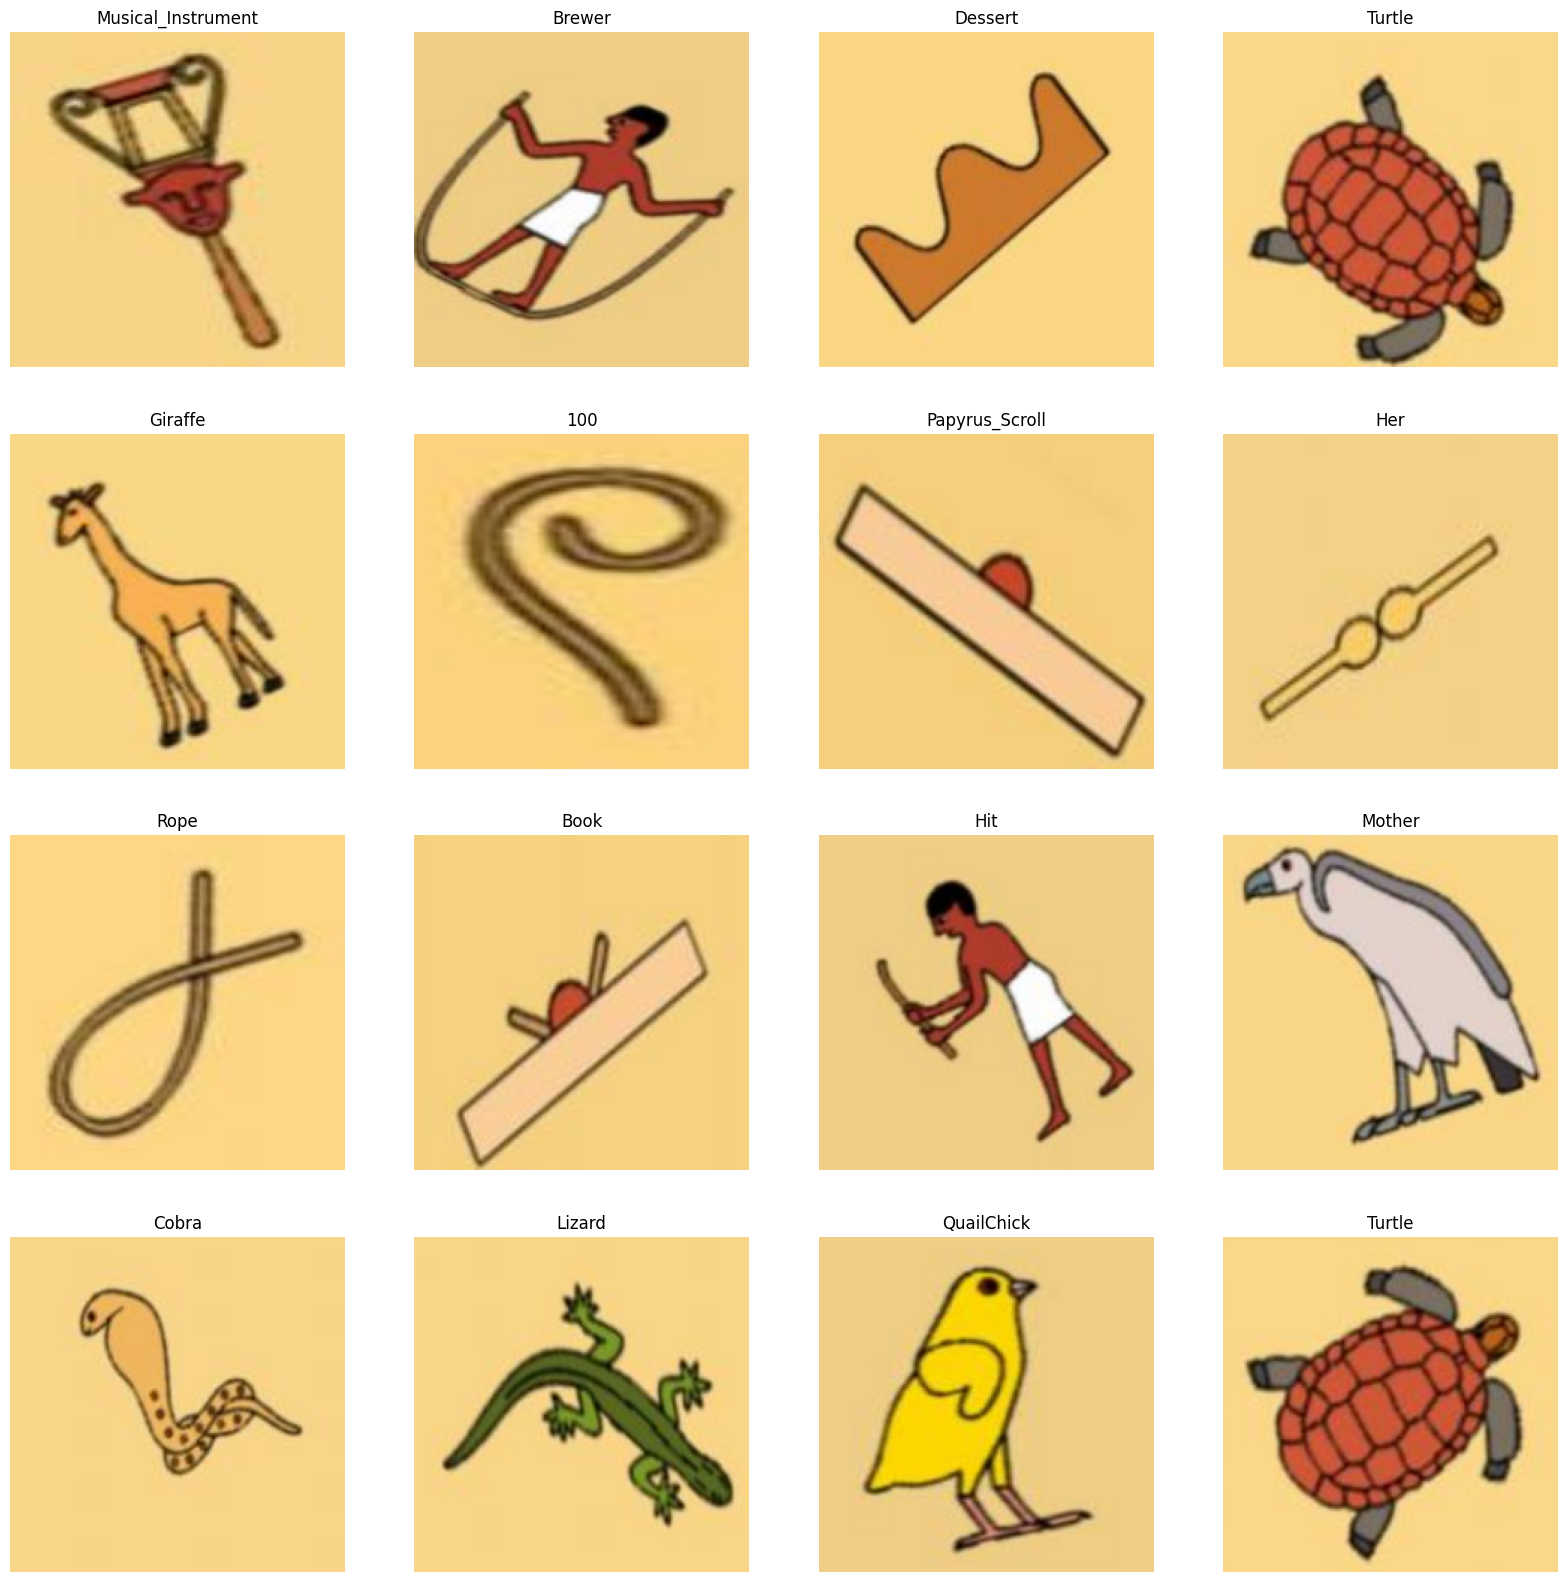

In [6]:
plt.figure(figsize=(20,20))
for n,i in enumerate(np.random.randint(0,len(train_df),16)):
    plt.subplot(4,4,n+1)
    plt.imshow(x_train[i])
    plt.title(y_train[i])
    plt.axis('off')
plt.show()

In [7]:
valid_df = pd.read_csv(valid_annotation_path)
valid_df

,filename,width,height,class,xmin,ymin,xmax,ymax
0,hit-29-_jpg.rf.0002460aa57927fd78f439dfae18698...,640,640,Hit,204,177,355,371
1,this-21-_jpg.rf.00392809c20fae35e692ba71dcb8a5...,640,640,This,170,213,282,369
2,turtle-15-_jpg.rf.00ca6ad63e61fc66d330c698e50e...,640,640,Turtle,280,247,425,399
3,mascot-20-_jpg.rf.0100543269029e643b6351c66771...,640,640,Mascot,117,315,283,482
4,meet-26-_jpg.rf.015f393754837d733509c11522977a...,640,640,Meet,214,192,358,351
...,...,...,...,...,...,...,...,...
773,at-25-_jpg.rf.fd87317f973f526211b27796bf590772...,640,640,At,141,275,280,379
774,face-36-_jpg.rf.fca2ade63812319313aff9a7e15a46...,640,640,Face,211,118,316,282
775,to-protect-21-_jpg.rf.ff24119a4ed92fd93029298f...,640,640,To_Protect,258,239,375,350
776,quailchick-39-_jpg.rf.fc828f15ed2815fa443e7b3a...,640,640,QuailChick,265,107,390,293


In [8]:
x_valid = []
y_valid = []
for i in tqdm(range(len(valid_df))):
    img = cv2.imread(f"{valid_path}/{valid_df['filename'][i]}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = img[valid_df['ymin'][i]:valid_df['ymax'][i], valid_df['xmin'][i]:valid_df['xmax'][i]]
    img = cv2.resize(img, (img_size, img_size))
    x_valid.append(img)
    y_valid.append(valid_df['class'][i])

100%|██████████| 778/778 [00:09<00:00, 77.90it/s]


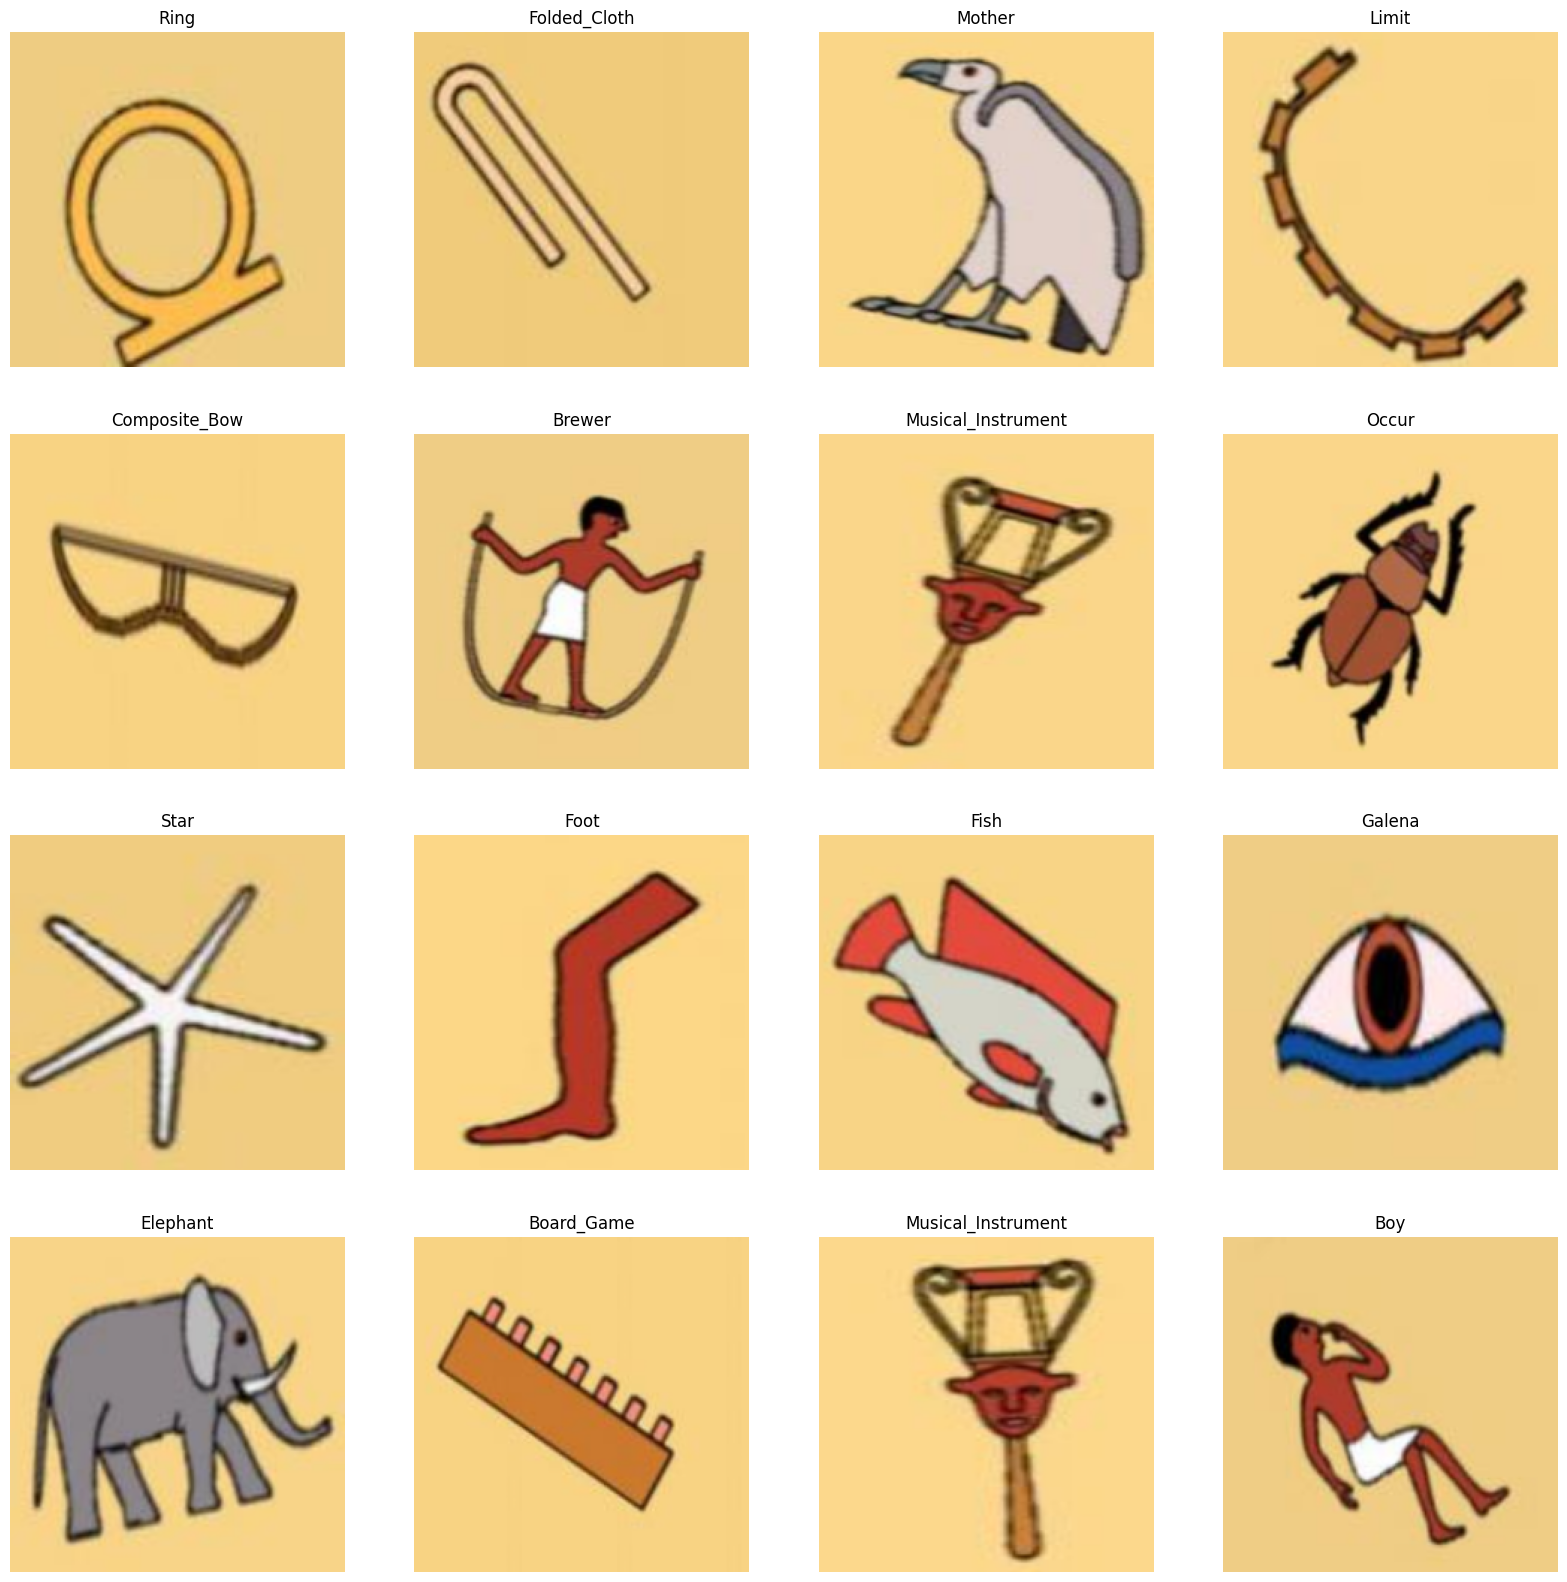

In [9]:
plt.figure(figsize=(20,20))
for n,i in enumerate(np.random.randint(0,len(valid_df),16)):
    plt.subplot(4,4,n+1)
    plt.imshow(x_valid[i])
    plt.title(y_valid[i])
    plt.axis('off')
plt.show()

In [10]:
test_df = pd.read_csv(test_annotation_path)
test_df

,filename,width,height,class,xmin,ymin,xmax,ymax
0,pair-13-_jpg.rf.00b5fe51fba9b40ddf2bf212cfa638...,640,640,Pair,279,252,413,361
1,papyrus-scroll-7-_jpg.rf.057bc680e540fcf9c8823...,640,640,Papyrus_Scroll,185,349,317,437
2,belongs-1-_jpg.rf.02044dee3ffba707db0388af036f...,640,640,Belongs,138,167,278,298
3,one-27-_jpg.rf.0c1b097a5ad422d790d896597e55dac...,640,640,One,401,341,451,408
4,hit-13-_jpg.rf.0919df39b6c2334496ec5ed6ed766f4...,640,640,Hit,238,115,382,337
...,...,...,...,...,...,...,...,...
384,galena-26-_jpg.rf.fcc57538723f2066cfbd7fd575fd...,640,640,Galena,280,152,391,294
385,he-14-_jpg.rf.fb84cd72fa58aa6f22e10f4da42bce21...,640,640,He,111,161,238,351
386,nurse-22-_jpg.rf.ecfc6e038c9ef509efb115d0f7ccc...,640,640,Nurse,285,249,402,380
387,leg-7-_jpg.rf.fdbf2457613b7587bc5e47da2c41611b...,640,640,Leg,382,166,554,295


In [11]:
x_test = []
y_test = []
for i in tqdm(range(len(test_df))):
    img = cv2.imread(f"{test_path}/{test_df['filename'][i]}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = img[test_df['ymin'][i]:test_df['ymax'][i], test_df['xmin'][i]:test_df['xmax'][i]]
    img = cv2.resize(img, (img_size, img_size))
    x_test.append(img)
    y_test.append(test_df['class'][i])

100%|██████████| 389/389 [00:04<00:00, 83.78it/s]


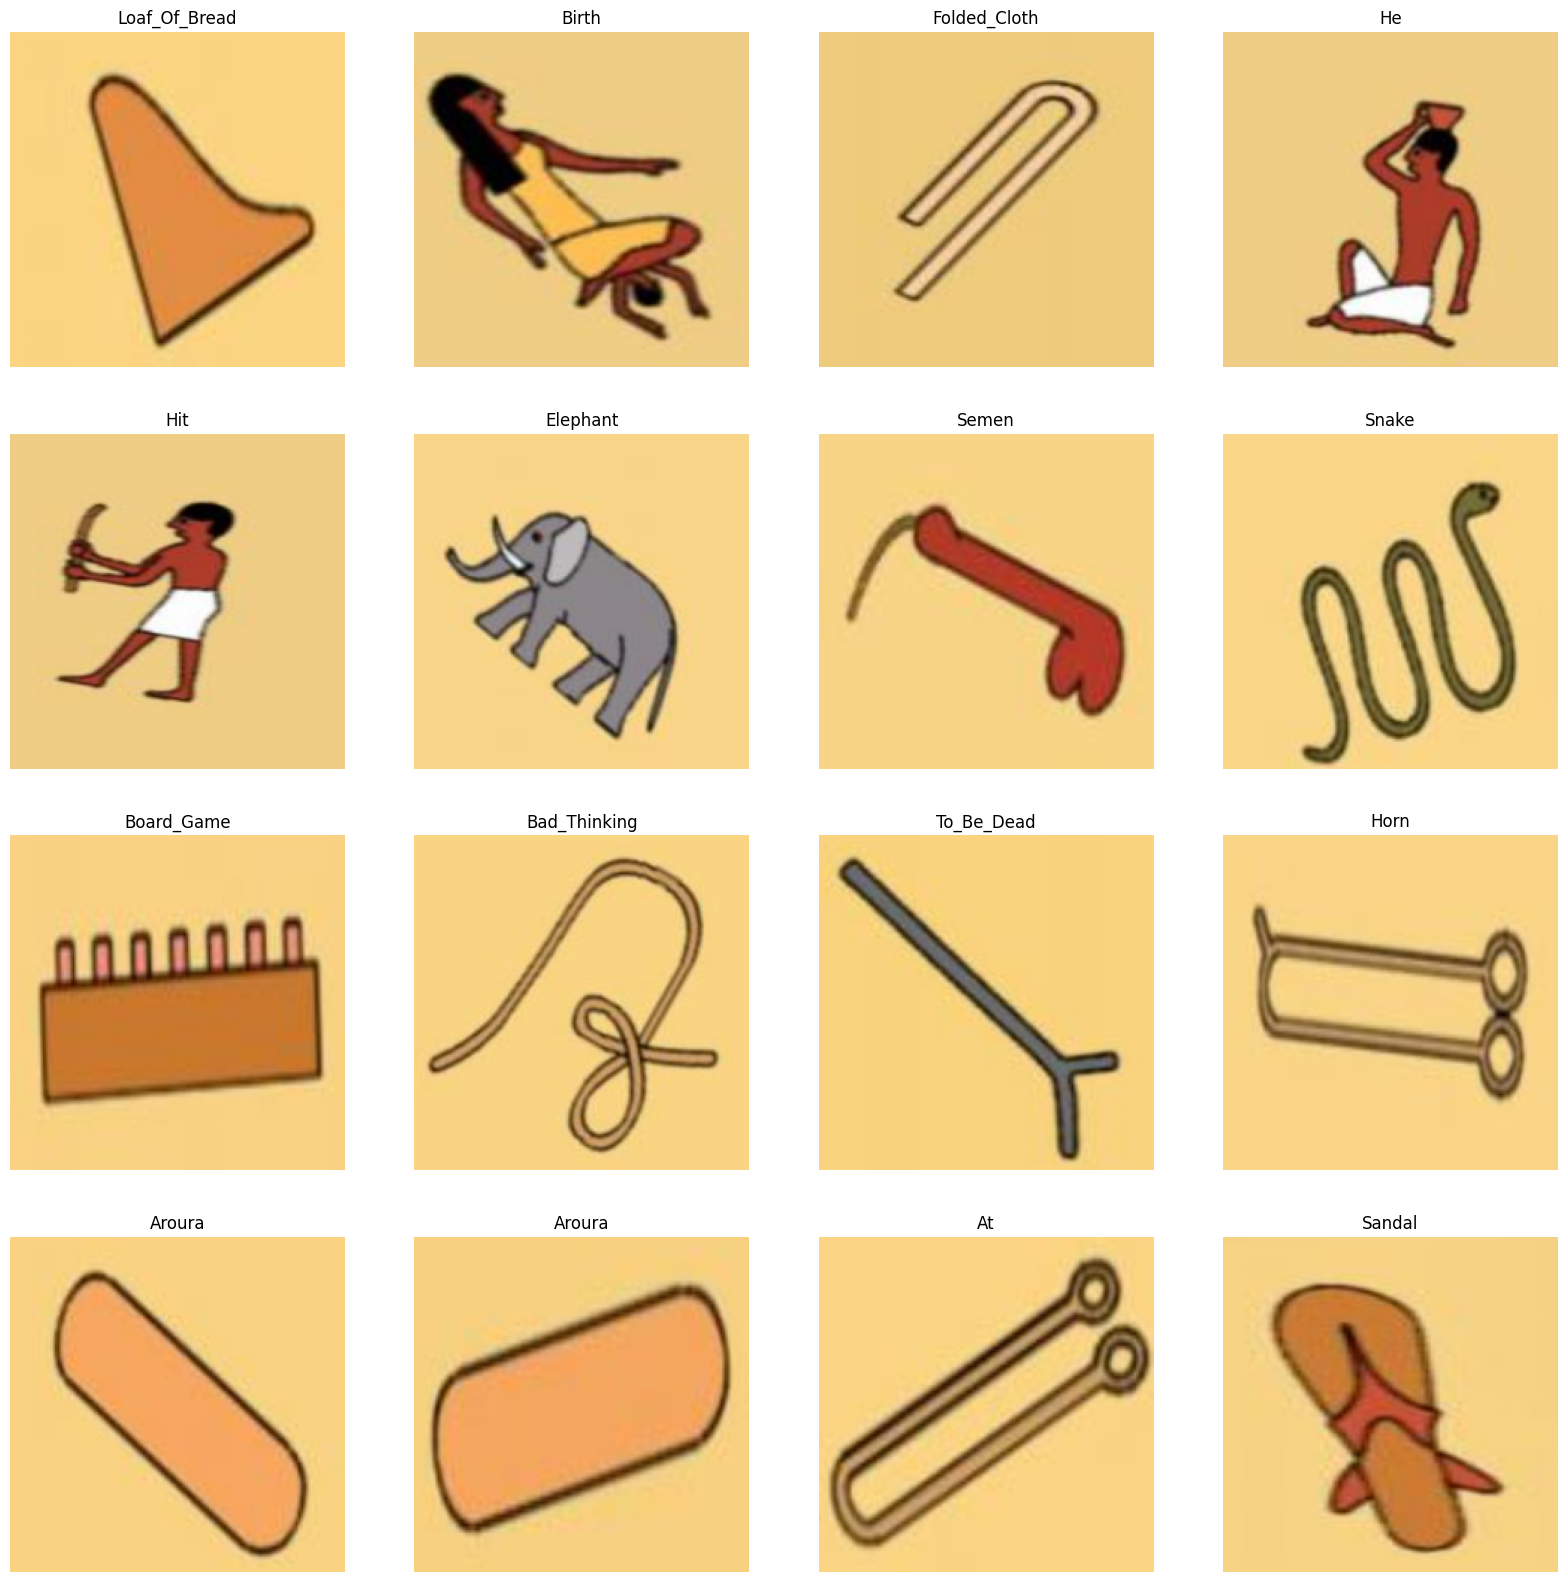

In [12]:
plt.figure(figsize=(20,20))
for n,i in enumerate(np.random.randint(0,len(test_df),16)):
    plt.subplot(4,4,n+1)
    plt.imshow(x_test[i])
    plt.title(y_test[i])
    plt.axis('off')
plt.show()

In [ ]:
# Fit one mapping on training labels; validation/test splits must share it.
y_train_labels = np.asarray(y_train)
y_valid_labels = np.asarray(y_valid)
y_test_labels = np.asarray(y_test)
class_encoder.fit(y_train_labels)
for split_name, labels in (("validation", y_valid_labels), ("test", y_test_labels)):
    unknown_classes = sorted(set(labels) - set(class_encoder.classes_))
    if unknown_classes:
        raise ValueError(f"{split_name} contains classes absent from training data: {unknown_classes}")
n_classes = len(class_encoder.classes_)
y_train = tf.keras.utils.to_categorical(class_encoder.transform(y_train_labels), num_classes=n_classes)
y_valid = tf.keras.utils.to_categorical(class_encoder.transform(y_valid_labels), num_classes=n_classes)
y_test = tf.keras.utils.to_categorical(class_encoder.transform(y_test_labels), num_classes=n_classes)


In [14]:
x_train = np.array(x_train)
x_valid = np.array(x_valid)
x_test = np.array(x_test)

In [15]:
models = { 
"Xception": tf.keras.applications.Xception,

"VGG16": tf.keras.applications.VGG16,

"VGG19": tf.keras.applications.VGG19,

"ResNet50": tf.keras.applications.ResNet50,

"ResNet101": tf.keras.applications.ResNet101,

"ResNet152": tf.keras.applications.ResNet152,

"InceptionV3": tf.keras.applications.InceptionV3,

"MobileNet": tf.keras.applications.MobileNet,
    
"MobileNetV2": tf.keras.applications.MobileNetV2,

"DenseNet121": tf.keras.applications.DenseNet121,

"DenseNet169": tf.keras.applications.DenseNet169,

"DenseNet201": tf.keras.applications.DenseNet201,

"NASNetMobile": tf.keras.applications.NASNetMobile,

"NASNetLarge": tf.keras.applications.NASNetLarge,

"EfficientNetB0": tf.keras.applications.EfficientNetB0,

"EfficientNetB1": tf.keras.applications.EfficientNetB1,

"EfficientNetB2": tf.keras.applications.EfficientNetB2,

"EfficientNetB3": tf.keras.applications.EfficientNetB3,

"EfficientNetB4": tf.keras.applications.EfficientNetB4,
    
"EfficientNetB5": tf.keras.applications.EfficientNetB5,

"EfficientNetB6": tf.keras.applications.EfficientNetB6,

"EfficientNetB7": tf.keras.applications.EfficientNetB7
}

In [ ]:
input_shape = (224, 224, 3)  

inputs = tf.keras.Input(shape=input_shape)
print(inputs )
model_name='ResNet152'
base_model = models[model_name](include_top=False, weights='imagenet', input_tensor=inputs)
base_model.trainable = False

x = tf.keras.layers.Flatten()(base_model.output)
x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(64, activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(n_classes, activation='softmax')(x)

model = tf.keras.models.Model(inputs = inputs, outputs = outputs)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)

model.compile(loss="categorical_crossentropy", optimizer= optimizer, metrics=["accuracy",'precision','recall'])

model.summary()

In [17]:
early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

model_checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

model_ReduceLROnPlateau = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=15, min_lr=0.000001)

callbacks=[early_stopping,model_checkpoint,model_ReduceLROnPlateau]

In [ ]:
history = model.fit(
                x_train,
                y_train,
                epochs = 20, 
                validation_data = (x_valid, y_valid),
                batch_size = 16,
                callbacks = callbacks,
                shuffle = True)

In [19]:
import seaborn as sns
sns.set()

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

precision = history.history['precision']
val_precision = history.history['val_precision']

recall =history.history['recall']
val_recall =history.history['val_recall']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(loss) + 1)

In [ ]:
plt.plot(epochs, acc, color='green', label='Training Accuracy')
plt.plot(epochs, val_acc, color='blue', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.ylim(0,1.02)
plt.show()

In [ ]:
plt.figure()
plt.plot(epochs, precision, color='green', label='Training precision')
plt.plot(epochs, val_precision, color='red', label='Validation precision')
plt.title('Training and Validation precision')
plt.xlabel('Epoch')
plt.ylabel('precision')
plt.legend()
plt.ylim(0,1.02)
plt.show()

In [ ]:
plt.figure()
plt.plot(epochs, recall, color='green', label='Training Recall')
plt.plot(epochs, val_recall, color='red', label='Validation Recall')
plt.title('Training and Validation Recall')
plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.legend()
plt.ylim(0,1.02)
plt.show()

In [ ]:
plt.figure()
plt.plot(epochs, loss, color='green', label='Training Loss')
plt.plot(epochs, val_loss, color='red', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.ylim(0,0.2)
plt.show()

In [ ]:
model_evaluate = model.evaluate(x_train,y_train)
print("Loss     : ",model_evaluate[0])
print("Accuracy : ",model_evaluate[1])
print("Precision  : ",model_evaluate[2])
print("Recall : ",model_evaluate[3])

In [ ]:
model_evaluate = model.evaluate(x_valid,y_valid)
print("Loss     : ",model_evaluate[0])
print("Accuracy : ",model_evaluate[1])
print("Precision  : ",model_evaluate[2])
print("Recall : ",model_evaluate[3])

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score,accuracy_score

y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

y_train_pred_class = np.argmax(y_train_pred, axis=1)
y_test_pred_class = np.argmax(y_test_pred, axis=1)

y_train_true = np.argmax(y_train, axis=1)
y_test_true = np.argmax(y_test, axis=1)

accuracy_train = accuracy_score(y_train_true, y_train_pred_class)
accuracy_test = accuracy_score(y_test_true, y_test_pred_class)

f1_train = f1_score(y_train_true, y_train_pred_class, average='weighted')
f1_test = f1_score(y_test_true, y_test_pred_class, average='weighted')

precision_train = precision_score(y_train_true, y_train_pred_class, average='weighted')
precision_test = precision_score(y_test_true, y_test_pred_class, average='weighted')

recall_train = recall_score(y_train_true, y_train_pred_class, average='weighted')
recall_test = recall_score(y_test_true, y_test_pred_class, average='weighted')

print(f"Training Accuracy: {accuracy_train:.2f}")
print(f"Test Accuracy: {accuracy_test:.2f}")
print(f"Training F1 Score: {f1_train:.2f}")
print(f"Test F1 Score: {f1_test:.2f}")
print(f"Training Precision: {precision_train:.2f}")
print(f"Test Precision: {precision_test:.2f}")
print(f"Training Recall: {recall_train:.2f}")
print(f"Test Recall: {recall_test:.2f}")

In [ ]:
data = {
    'model': ['TL(ResNet152)'],
    'Accuracy train': [accuracy_train],
    'Accuracy test': [accuracy_test],
    'Precision train': [precision_train],
    'Precision test': [precision_test],
    'Recall train': [recall_train],
    'Recall test': [recall_test],
    'F1-score train': [f1_train],
    'F1-score test': [f1_test]
}


metrics_df = pd.DataFrame(data)
metrics_df